# T2 · Calidad de los datos, métricas de calidad y ranking de inspección

**E1 Diagnóstico · Caso Aguas Andinas · Responsable: Byron** · *Datos 100% simulados con fines docentes; no representan instalaciones ni resultados reales de la empresa.*

## En simple

Cada hora, cada uno de los **30 sectores** de la red envía una **lectura**: una fila del CSV con el agua que entró y salió del sector, la presión, la energía de las bombas y los minutos sin agua. Este notebook revisa **qué tan confiables son esas lecturas**: cuántas vienen malas, de qué tipo, en qué lote y en qué sector, y cuánto distorsionan los indicadores del negocio si no se tratan bien.

Cada problema se mide con una **regla de calidad** (por ejemplo, "la unidad debe ser m3 o L"). Cada regla indica cuántas filas revisó (**denominador**) y cuántas fallaron, y clasifica el problema como:
- **defecto**: incumple el contrato del dato, como una unidad desconocida o una fecha imposible. Algunos son *recuperables* porque su formato está documentado (coma decimal, fecha dd/mm);
- **extremo plausible**: un valor raro pero posible; se marca y no se borra;
- **ausencia estructural**: falta por diseño, como las tarifas antes de agosto.

**Aquí no se limpia nada:** solo se mide y se propone un tratamiento. La limpieza corresponde a la E2.

| Producto | Ruta |
|---|---|
| Matriz de reglas (Word) | `salidas/tablas/matriz_reglas.csv` |
| Perfil de calidad por lote y segmento (Word) | `salidas/tablas/perfil_calidad.csv` |
| Sesgo en KPI | `salidas/tablas/T2_sesgo_kpi.csv` |
| Fichas de las 6 métricas de calidad | `salidas/tablas/T2_fichas_calidad.csv` |
| Confiabilidad por sector (contrato del README) | `salidas/tablas/T2_por_sector.csv` |
| Figuras | `salidas/figuras/T2_*.png` |

**Decisiones del grupo usadas aquí** ([decisiones.md](decisiones.md)):
- **D-01:** el atraso de carga se mide con un umbral de 2 horas.
- **D-02:** la confiabilidad define el tipo de inspección.
- **D-03:** el ranking espera las tablas de T3 y T4.

Las reglas están en el módulo [T2_reglas.py](T2_reglas.py), para reutilizarlas en la E2 (antes/después) y la E4 (reingesta). Ejecutar desde la carpeta `E1/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import comun
import T2_reglas as rq

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
TABLAS = comun.RAIZ / "E1" / "salidas" / "tablas"
FIGURAS = comun.RAIZ / "E1" / "salidas" / "figuras"
P = comun.PALETA
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def n(x):
    """Entero con separador de miles chileno."""
    return f"{int(x):,}".replace(",", ".")


def pct(x, d=1):
    return f"{x:.{d}f}".replace(".", ",") + "%"


def nota(fig, extra=""):
    fig.text(0.01, -0.03, comun.NOTA_FUENTE + (" · " + extra if extra else ""), fontsize=8, color=P["neutro"], ha="left")


comun.verificar_hashes()
df = comun.parse_exploratorio(comun.cargar_lotes())
ctx = rq.contexto()
ev = rq.evaluar_reglas(df, ctx)
print(f"{n(len(df))} filas de telemetría en {df.lote.nunique()} lotes; {len(ev)} reglas evaluadas por fila")

253.404 filas de telemetría en 3 lotes; 22 reglas evaluadas por fila


## 1. Estructura por lote

Antes de medir errores, se confirma que cada lote tiene las filas y columnas que declara `metadatos.json` y que sus fechas válidas caen en su período.

In [2]:
meta_lote = {f["archivo"].split("/")[1]: f for f in comun.META["files"] if f["archivo"].endswith("telemetria_horaria.csv")}
estructura = pd.DataFrame([{
    "lote": l,
    "filas": int(df.lote.eq(l).sum()),
    "filas_metadatos": meta_lote[l]["filas"],
    "columnas": len(rq.COLS_ORIGINALES),
    "columnas_metadatos": meta_lote[l]["columnas"],
    "fecha_min": df.loc[df.lote.eq(l), "fecha"].min(),
    "fecha_max": df.loc[df.lote.eq(l), "fecha"].max(),
    "periodo_esperado": " a ".join(rq.PERIODO_LOTE[l]) + " (fin exclusivo)",
} for l in rq.LOTES])
assert (estructura.filas == estructura.filas_metadatos).all()
assert (estructura.columnas == estructura.columnas_metadatos).all()
estructura

,lote,filas,filas_metadatos,columnas,columnas_metadatos,fecha_min,fecha_max,periodo_esperado
0,base,130972,130972,11,11,2025-01-01 00:00:00+00:00,2025-06-30 23:00:00+00:00,2025-01-01 a 2025-07-01 (fin exclusivo)
1,actualizacion,22432,22432,11,11,2025-07-01 00:00:00+00:00,2025-07-31 23:00:00+00:00,2025-07-01 a 2025-08-01 (fin exclusivo)
2,ampliacion,100000,100000,11,11,2025-08-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,2025-08-01 a 2026-01-01 (fin exclusivo)


Los tres lotes coinciden con `metadatos.json` en filas (130.972 + 22.432 + 100.000 = 253.404) y columnas (11), y sus fechas válidas quedan dentro del período de cada lote (RQ-VAL-03 = 0).

## 2. Matriz de reglas (`matriz_reglas.csv`)

Una fila por **regla × lote**, con las columnas de `plantilla_reglas_calidad.csv` más `lote` y `clasificacion`. Las reglas sobre catálogos y tablas complementarias usan `lote = catalogo`.

**Denominadores condicionales.** Cada regla se mide sobre las filas donde tiene sentido evaluarla, para no contar dos veces un mismo problema. Por ejemplo, *salida > entrada* (RQ-CON-01) solo se evalúa donde ambos volúmenes son válidos y la entrada no es negativa: en ene-jul, **todos** los casos de salida > entrada venían de una entrada negativa, que ya cuenta en RQ-VAL-07.

In [3]:
matriz = rq.matriz_reglas(df, ev, ctx)
matriz.to_csv(TABLAS / "matriz_reglas.csv", index=False)
tel = matriz[matriz.lote.isin(rq.LOTES)].copy()
tel["pct_fallidas"] = 100 * tel.filas_fallidas / tel.filas_evaluadas
resumen = (tel.pivot_table(index=["regla_id", "clasificacion"], columns="lote", values="pct_fallidas", sort=False)[rq.LOTES]
           .round(3).reset_index()
           .merge(tel.groupby("regla_id", sort=False)[["filas_fallidas", "filas_evaluadas"]].sum().reset_index(), on="regla_id"))
resumen.insert(1, "regla", resumen.regla_id.map(rq.NOMBRE_CORTO))
print(f"matriz_reglas.csv: {len(matriz)} filas · {matriz.regla_id.nunique()} reglas · % de filas fallidas por lote:")
resumen

matriz_reglas.csv: 76 filas · 27 reglas · % de filas fallidas por lote:


,regla_id,regla,clasificacion,base,actualizacion,ampliacion,filas_fallidas,filas_evaluadas
0,RQ-UNI-01,Copia exacta de fila,defecto,0.498,0.499,0.000,764,253404
1,RQ-UNI-02,Clave con contenido distinto,defecto,0.000,0.000,0.000,0,253404
2,RQ-UNI-03,Sector-hora repetida,defecto,0.000,0.000,0.000,0,251682
3,RQ-VAL-01,Fecha imposible,defecto,0.100,0.098,0.200,353,253404
4,RQ-VAL-02,Fecha dd/mm (recuperable),defecto,0.000,0.000,0.500,500,253404
5,RQ-VAL-03,Fecha fuera del lote,defecto,0.000,0.000,0.000,0,253051
6,RQ-VAL-04,Coma decimal (recuperable),defecto,0.000,0.000,0.600,600,253404
7,RQ-VAL-05,Volumen con texto (PENDIENTE),defecto,0.000,0.000,0.256,250,249672
8,RQ-VAL-06,Unidad desconocida,defecto,0.000,0.000,0.250,250,253404
9,RQ-VAL-07,Volumen de entrada negativo,defecto,0.403,0.401,0.410,1012,249422


In [4]:
matriz.loc[matriz.lote.eq("catalogo"), ["regla_id", "tabla", "condicion", "filas_evaluadas", "filas_fallidas", "clasificacion"]]

,regla_id,tabla,condicion,filas_evaluadas,filas_fallidas,clasificacion
69,RQ-CAT-01,sectores,Clave esperada repetida en la tabla (metadatos...,30,0,defecto
70,RQ-CAT-01,sectores_historial,Clave esperada repetida en la tabla (metadatos...,60,0,defecto
71,RQ-CAT-01,tarifas_energia,Clave esperada repetida en la tabla (metadatos...,150,0,defecto
72,RQ-CAT-01,metas_2025_ancho,Clave esperada repetida en la tabla (metadatos...,30,0,defecto
73,RQ-CAT-02,sectores_historial,Vigencias del sector con solape o hueco dentro...,30,0,defecto
74,RQ-CAT-03,tarifas_energia,Tarifa no numérica o ≤ 0,150,0,defecto
75,RQ-AUS-02,metas_ancho,metas_ancho.csv no tiene metas para ago-dic,30,30,ausencia_estructural


**Lectura de la matriz:**

- **Observación:**
  - **Copias exactas:** solo existen en ene-jul (652 de 130.972 filas en base y 112 de 22.432 en actualización, 0,5% en cada caso). La ampliación no tiene claves repetidas.
  - **Defectos nuevos en ago-dic:** la ampliación trae **7 tipos de defecto que no existían en ene-jul**:
    - coma decimal (600);
    - fecha dd/mm (500);
    - volumen `PENDIENTE` (250);
    - unidad desconocida (250);
    - interrupción de 90 min (350);
    - salida > entrada con entrada válida (350);
    - carga anterior a la hora medida (300).
  - **Cobertura:**
    - en ene-jul, cada sector-hora llegó exactamente una vez (más las copias), y solo 0,3% de las sector-horas queda sin lectura válida (por fecha imposible o sector `NO_EXISTE`);
    - en ago-dic falta el **9,7%** (10.660 de 110.160): 10.160 sector-horas nunca llegaron y 500 llegaron inválidas.
- **Hipótesis:** el lote de ampliación pasó por un proceso de captura o integración distinto (otros formatos, otro reloj de carga). Es una hipótesis: los datos no permiten afirmarlo.
- **Decisión o acción:**
  - los formatos recuperables (coma decimal, fecha dd/mm, modo con espacios) se convierten en la E2 con la regla documentada;
  - los defectos no recuperables se excluyen de los KPI afectados, sin imputar.
- **Extremos plausibles:**
  - ningún volumen supera la capacidad del sector;
  - hay 146 energías y **4.506 presiones** fuera de 1,5 RIC de su sector. La mayoría son presiones **bajas** (3.723 bajo la mediana), con más casos en A-S21 a A-S25. Es una señal operacional para T3 (heatmap de presión) y T4, no un defecto.
- **Ausencias estructurales (no son defectos):** no hay tarifas en ene-jul (153.251 filas) y `metas_ancho` no trae metas para ago-dic, porque la sustituye `metas_2025_ancho`.

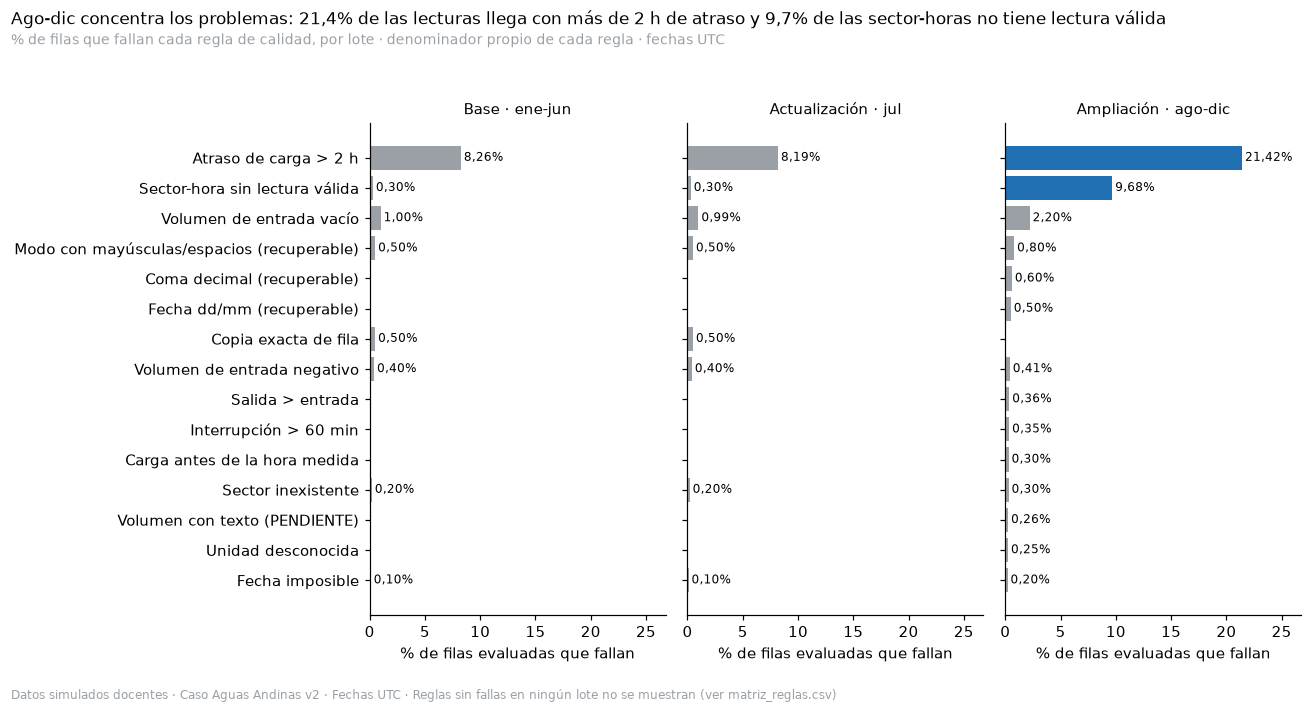

In [5]:
graficar = tel[tel.clasificacion.eq("defecto")]
con_fallas = graficar.groupby("regla_id").filas_fallidas.sum()
orden = graficar[graficar.regla_id.isin(con_fallas[con_fallas > 0].index)].groupby("regla_id").pct_fallidas.max().sort_values().index
pa = tel.set_index(["regla_id", "lote"]).pct_fallidas
destacar = {("RQ-OPO-02", "ampliacion"), ("RQ-COM-02", "ampliacion")}

fig, axes = plt.subplots(1, 3, sharey=True, figsize=(12, 6.2))
xmax = pa.loc[list(orden)].max() * 1.25
for ax, lote, titulo in zip(axes, rq.LOTES, ["Base · ene-jun", "Actualización · jul", "Ampliación · ago-dic"]):
    valores = [pa.get((r, lote), 0) for r in orden]
    colores = [P["acento"] if (r, lote) in destacar else P["neutro"] for r in orden]
    ax.barh([rq.NOMBRE_CORTO[r] for r in orden], valores, color=colores)
    for y, v in enumerate(valores):
        if v > 0:
            ax.text(v + xmax * 0.01, y, pct(v, 2), va="center", fontsize=8)
    ax.set_xlim(0, xmax)
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel("% de filas evaluadas que fallan")
amp = pa.xs("ampliacion", level="lote")
fig.suptitle(f"Ago-dic concentra los problemas: {pct(amp['RQ-OPO-02'])} de las lecturas llega con más de 2 h de atraso "
             f"y {pct(amp['RQ-COM-02'])} de las sector-horas no tiene lectura válida", fontsize=11, x=0.01, ha="left")
fig.text(0.01, 0.93, "% de filas que fallan cada regla de calidad, por lote · denominador propio de cada regla · fechas UTC",
         fontsize=9, color=P["neutro"])
fig.tight_layout(rect=(0, 0, 1, 0.92))
nota(fig, "Reglas sin fallas en ningún lote no se muestran (ver matriz_reglas.csv)")
fig.savefig(FIGURAS / "T2_reglas_por_lote.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:**
- **Observación:** los dos problemas más extendidos son de **oportunidad** (atraso de carga) y **cobertura** (sector-horas sin lectura válida), y ambos se agravan fuertemente en ago-dic. El resto de los defectos afecta menos del 1% de las filas evaluadas en cada lote.
- **Por qué importa:** la decisión se toma con datos de ago-dic, el período con tarifas y conexiones vigentes. Ese es justamente el lote menos confiable.
- **Límite:** cada porcentaje usa su propio denominador (ver la columna `denominador` de la matriz), así que las barras no se pueden sumar.

## 3. Oportunidad: atraso de carga (decisión D-01)

El atraso es `cargado_en - fecha`: cuánto tardó la lectura en llegar a la base de datos después de la hora medida. `metadatos.json` declara `"latency": 2` **sin unidad**. Se interpretó como **2 horas** porque calza con la telemetría horaria y porque con 2 días ninguna lectura fallaría ([D-01](decisiones.md)). Como el umbral es una decisión del grupo, se muestra cómo cambia el resultado con 1, 3 y 6 horas.

In [6]:
atraso = rq.atraso_horas(df)
sensibilidad = pd.DataFrame({
    f"> {u} h": {l: 100 * ((atraso > u) & df.lote.eq(l)).sum() / (atraso.notna() & df.lote.eq(l)).sum() for l in rq.LOTES}
    for u in rq.SENSIBILIDAD_ATRASO_H})
sensibilidad.loc["total"] = {f"> {u} h": 100 * (atraso > u).sum() / atraso.notna().sum() for u in rq.SENSIBILIDAD_ATRASO_H}
print(f"% de lecturas con atraso mayor al umbral (denominador: {n(atraso.notna().sum())} lecturas con ambas fechas válidas)")
sensibilidad.round(2)

% de lecturas con atraso mayor al umbral (denominador: 253.051 lecturas con ambas fechas válidas)


,> 1 h,> 2 h,> 3 h,> 6 h
base,28.68,8.26,2.29,0.05
actualizacion,29.21,8.19,2.36,0.05
ampliacion,46.26,21.42,9.97,1.01
total,35.66,13.44,5.33,0.43


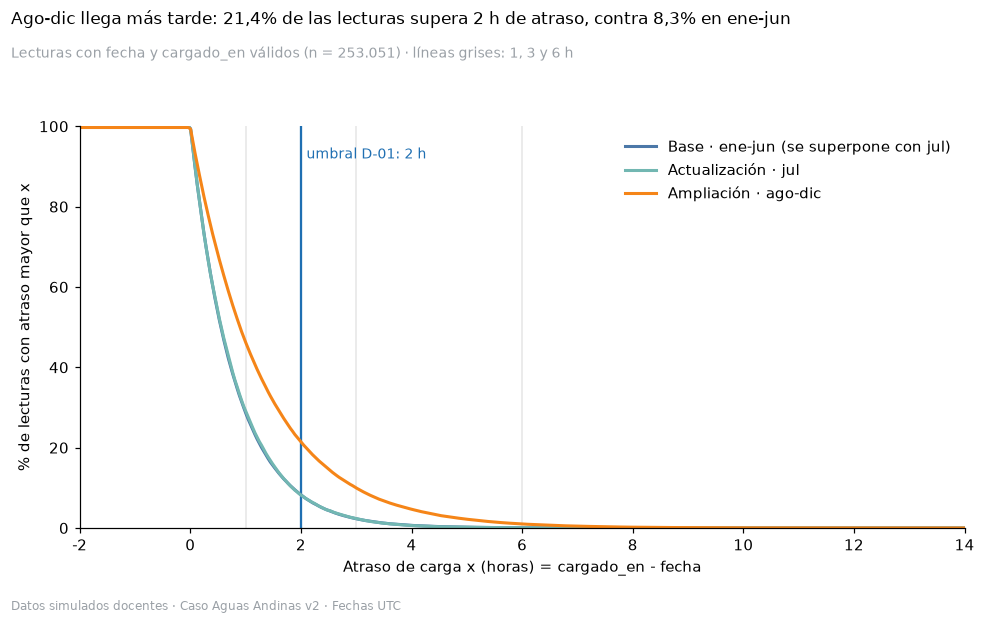

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.4))
x = np.linspace(-2, 14, 400)
for lote, etiqueta in zip(rq.LOTES, ["Base · ene-jun (se superpone con jul)", "Actualización · jul", "Ampliación · ago-dic"]):
    v = atraso[df.lote.eq(lote)].dropna().values
    ax.plot(x, [100 * (v > xi).mean() for xi in x], color=P[lote], lw=2, label=etiqueta)
for u in rq.SENSIBILIDAD_ATRASO_H:
    ax.axvline(u, color=P["acento"] if u == rq.UMBRAL_ATRASO_H else P["ausente"], lw=1.5 if u == rq.UMBRAL_ATRASO_H else 1, zorder=0)
ax.text(rq.UMBRAL_ATRASO_H + 0.1, 92, "umbral D-01: 2 h", color=P["acento"], fontsize=9)
ax.set_xlim(-2, 14)
ax.set_ylim(0, 100)
ax.set_xlabel("Atraso de carga x (horas) = cargado_en - fecha")
ax.set_ylabel("% de lecturas con atraso mayor que x")
ax.legend(frameon=False)
s2 = sensibilidad["> 2 h"]
fig.suptitle(f"Ago-dic llega más tarde: {pct(s2['ampliacion'])} de las lecturas supera 2 h de atraso, contra "
             f"{pct(s2['base'])} en ene-jun", fontsize=11, x=0.01, ha="left")
fig.text(0.01, 0.9, f"Lecturas con fecha y cargado_en válidos (n = {n(atraso.notna().sum())}) · líneas grises: 1, 3 y 6 h",
         fontsize=9, color=P["neutro"])
fig.tight_layout(rect=(0, 0, 1, 0.88))
nota(fig)
fig.savefig(FIGURAS / "T2_atraso_carga.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:**
- **Observación:**
  - con el umbral de 2 h, el 8,3% de las lecturas de base (y 8,2% de actualización) llega tarde, contra el **21,4% en ampliación**: 2,6 veces más;
  - la ampliación es peor con **cualquier** umbral: 46,3% vs. 28,7% sobre 1 h, 10,0% vs. 2,3% sobre 3 h y 1,0% vs. 0,05% sobre 6 h;
  - 300 lecturas de ampliación se cargaron **antes** de la hora que miden (RQ-OPO-01), algo imposible que apunta a un problema de reloj.
- **Hipótesis:** la integración de ago-dic tiene más demora en la transmisión, o un proceso de carga por tandas. No es verificable con estos datos.
- **Decisión o acción:**
  - el atraso no invalida los datos históricos, así que esas filas **no se excluyen** de los KPI;
  - en un dashboard operacional, sí obliga a advertir que las últimas horas pueden estar incompletas.
- **Límite:** el porcentaje exacto depende de la unidad elegida para `"latency": 2` (D-01). En cambio, la conclusión de que ago-dic llega más tarde **no depende del umbral**.

## 4. Perfil por lote y segmento (`perfil_calidad.csv`)

Una fila por **lote × segmento × campo**, para los segmentos `total`, `sector`, `mes` y `modo_operacion`. Hay dos conteos distintos:
- `nulos`: campo vacío en el archivo;
- `invalidos`: el valor existe pero incumple su contrato.

Los formatos recuperables (coma decimal, fecha dd/mm, modo con espacios) **no** cuentan como inválidos. Los volúmenes se resumen en m3 (min, p50, max) y las fechas, en UTC.

In [8]:
perfil = rq.perfil_calidad(df, ev)
perfil.to_csv(TABLAS / "perfil_calidad.csv", index=False)
print(f"perfil_calidad.csv: {n(len(perfil))} filas (lote × segmento × campo)")
(perfil[perfil.segmento_tipo.eq("total")]
 .pivot_table(index="campo", columns="lote", values=["pct_nulos", "pct_invalidos"], sort=False)
 .reindex(columns=rq.LOTES, level=1).round(3))

perfil_calidad.csv: 1.287 filas (lote × segmento × campo)


pct_nulos                          pct_invalidos                         
lote                      base actualizacion ampliacion          base actualizacion ampliacion
campo                                                                                         
medicion_id              0.000         0.000        0.0         0.498         0.499       0.00
fecha                    0.000         0.000        0.0         0.100         0.098       0.20
sector_id                0.000         0.000        0.0         0.202         0.201       0.30
volumen_entrada          0.999         0.994        2.2         0.399         0.397       0.65
volumen_salida           0.000         0.000        0.0         0.000         0.000       0.00
unidad_volumen           0.000         0.000        0.0         0.000         0.000       0.25
presion_bar              0.000         0.000        0.0         0.000         0.000       0.00
energia_kwh              0.000         0.000        0.0         0.000         0.000       0.00
minutos_interrupcion     0.000         0.000        0.0         0.000         0.000       0.35
modo_operacion           0.000         0.000        0.0         0.000         0.000       0.00
cargado_en               0.000         0.000        0.0         0.000         0.000       0.30

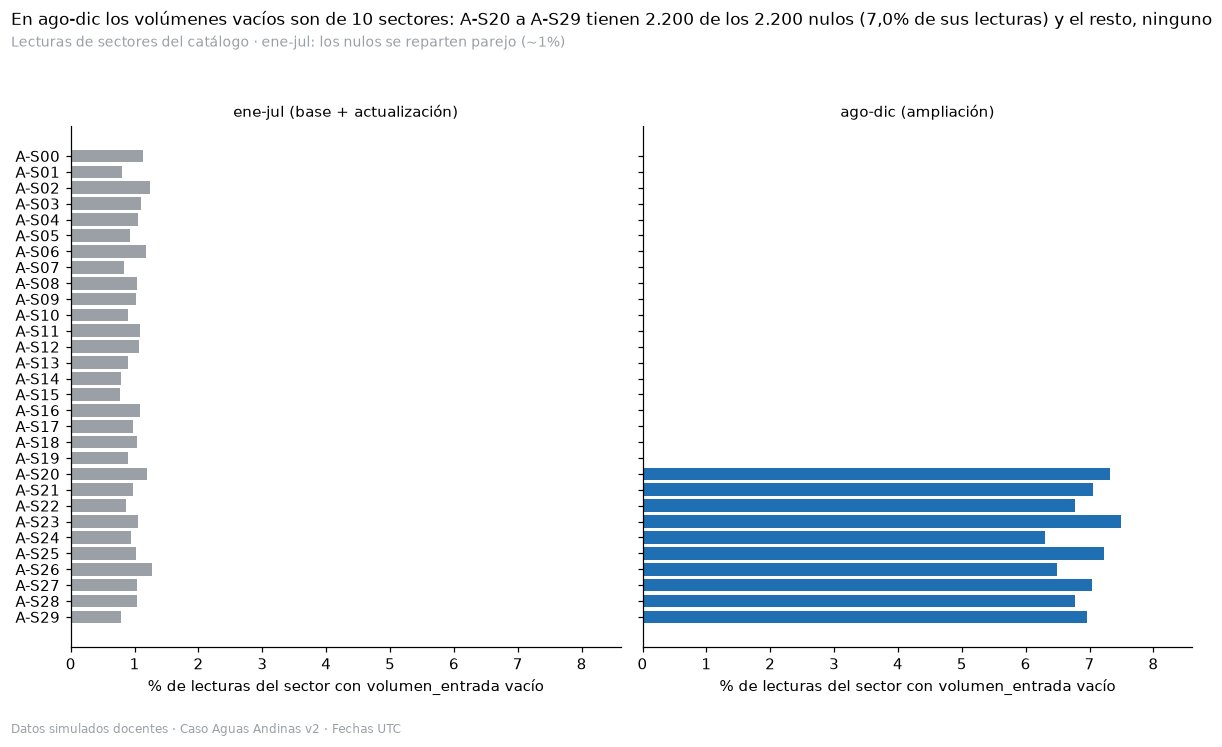

In [9]:
validos = df.sector_id.isin(ctx["sectores"].sector_id)
nulo = ev["RQ-COM-01"][0]
grupo = {"ene-jul (base + actualización)": df.lote.isin(["base", "actualizacion"]), "ago-dic (ampliación)": df.lote.eq("ampliacion")}
tasa = pd.DataFrame({k: 100 * (nulo & m & validos).groupby(df.sector_id).sum() / (m & validos).groupby(df.sector_id).sum()
                     for k, m in grupo.items()}).loc[sorted(ctx["sectores"].sector_id)]
s20 = [f"A-S{i}" for i in range(20, 30)]
amp_nulos = int((nulo & grupo["ago-dic (ampliación)"]).sum())
amp_nulos_s20 = int((nulo & grupo["ago-dic (ampliación)"] & df.sector_id.isin(s20)).sum())
tasa_s20 = 100 * amp_nulos_s20 / int((grupo["ago-dic (ampliación)"] & df.sector_id.isin(s20)).sum())

fig, axes = plt.subplots(1, 2, sharey=True, figsize=(11, 6.5))
for ax, col in zip(axes, tasa.columns):
    colores = [P["acento"] if (s in s20 and "ago" in col) else P["neutro"] for s in tasa.index]
    ax.barh(tasa.index, tasa[col], color=colores)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("% de lecturas del sector con volumen_entrada vacío")
    ax.set_xlim(0, tasa.values.max() * 1.15)
axes[0].invert_yaxis()
fig.suptitle(f"En ago-dic los volúmenes vacíos son de 10 sectores: A-S20 a A-S29 tienen {n(amp_nulos_s20)} de los {n(amp_nulos)} "
             f"nulos ({pct(tasa_s20)} de sus lecturas) y el resto, ninguno", fontsize=11, x=0.01, ha="left")
fig.text(0.01, 0.93, "Lecturas de sectores del catálogo · ene-jul: los nulos se reparten parejo (~1%)", fontsize=9, color=P["neutro"])
fig.tight_layout(rect=(0, 0, 1, 0.92))
nota(fig)
fig.savefig(FIGURAS / "T2_nulos_por_sector.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:**
- **Observación:** en ene-jul los volúmenes de entrada vacíos se reparten de forma pareja (cerca de 1% en todos los sectores). En ago-dic, en cambio, **los 2.200 nulos están en los sectores A-S20 a A-S29** (6,95% de sus lecturas) y en los otros 20 sectores no hay ninguno.
- **Hipótesis:** una falla de medición o de transmisión que afecta a ese grupo de sectores desde agosto. Es solo una hipótesis: los datos no muestran la causa.
- **Decisión o acción:**
  - un promedio sobre las lecturas disponibles de esos sectores puede ocultar justamente las horas con problemas;
  - según la decisión D-02, si alguno de ellos entra entre los 3 prioritarios, se propone **inspeccionar primero el sensor**.
- **Límite:** un nulo no dice si el sector tuvo agua o no; no se imputa 0.

## 5. Sesgo en los KPI: cuánto cambian según cómo se tratan los defectos

El Word pide *"estimar qué indicadores sufrirían mayor sesgo"*. Para responderlo se calculan tres KPI con el **tratamiento correcto** (referencia) y con cinco tratamientos **incorrectos**:
- diferencia de volúmenes (%) = Σ(entrada - salida) / Σ entrada;
- intensidad energética (kWh/m3) = Σ kWh / Σ m3 de entrada;
- continuidad simple (%) = 1 - Σ minutos / (60 × horas). Es simple porque no está ponderada por conexiones; la oficial la calcula T3.

La referencia es provisional; las fórmulas finales de los KPI son de T4.

In [10]:
sesgo = rq.sesgo_kpi(df, ev, ctx)
sesgo.to_csv(TABLAS / "T2_sesgo_kpi.csv", index=False)
(sesgo[sesgo.alcance.isin(["total", "ampliacion"])]
 .pivot_table(index="escenario", columns=["alcance", "kpi"], values="valor", sort=False).round(4))

alcance                                                               total                                                 ampliacion                                  
kpi                                                diferencia_volumenes_pct kwh_por_m3 continuidad_simple_pct diferencia_volumenes_pct kwh_por_m3 continuidad_simple_pct
escenario                                                                                                                                                               
Referencia (tratamiento correcto)                                   16.1042     0.2651                98.3933                  18.1815     0.2643                98.0098
Sin convertir litros a m3                                           16.3605     0.0015                98.3933                  17.6827     0.0011                98.0098
Sin deduplicar copias exactas                                       16.1001     0.2652                98.3938                  18.1815     0.2643                98.0098
Incluyendo entrada negativa y salida > entrada                      15.3330     0.2673                98.3933                  17.2772     0.2666                98.0098
Incluyendo minutos > 60                                             16.1042     0.2651                98.1869                  18.1815     0.2643                97.4892
Horas sin lectura tratadas como 0 min de interr...                      NaN        NaN                98.4634                      NaN        NaN                98.2087

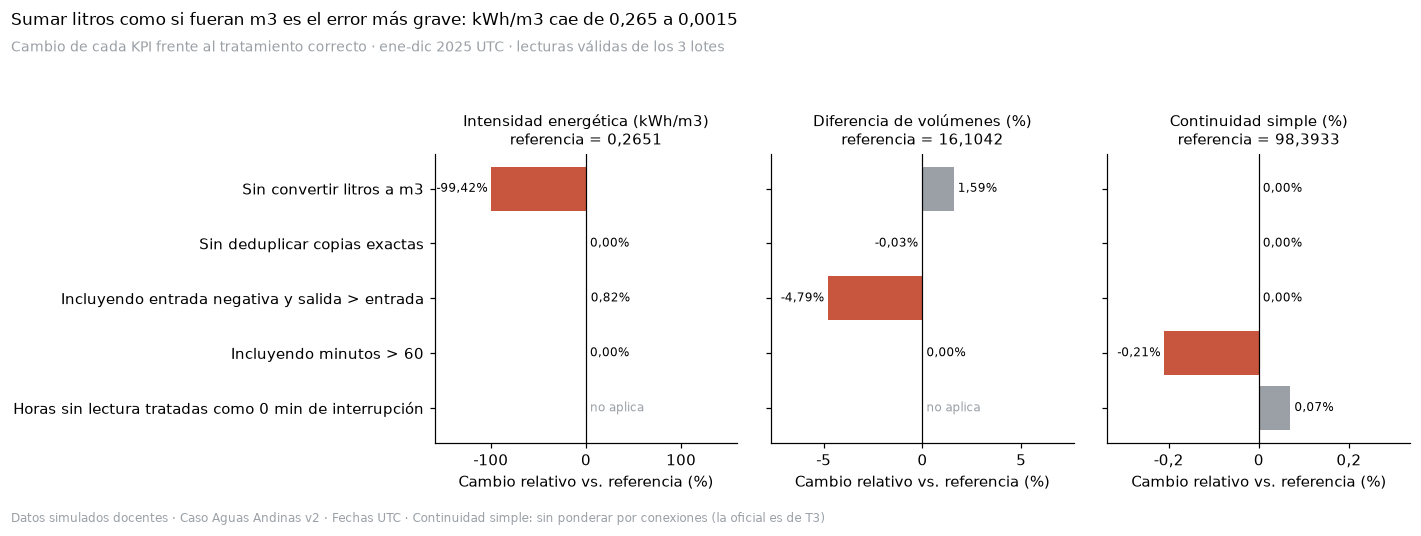

In [11]:
kpis = {"kwh_por_m3": "Intensidad energética (kWh/m3)", "diferencia_volumenes_pct": "Diferencia de volúmenes (%)",
        "continuidad_simple_pct": "Continuidad simple (%)"}
t = sesgo[sesgo.alcance.eq("total") & ~sesgo.escenario.str.startswith("Referencia")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
escenarios = list(dict.fromkeys(t.escenario))
for ax, (kpi, titulo) in zip(axes, kpis.items()):
    d = t[t.kpi.eq(kpi)].set_index("escenario").reindex(escenarios)
    valores = d.delta_relativo_pct.fillna(0)
    peor = valores.abs().idxmax()
    ax.barh(escenarios, valores, color=[P["alerta"] if e == peor and abs(valores[e]) > 0 else P["neutro"] for e in escenarios])
    ax.axvline(0, color="black", lw=0.8)
    for y, (e, v) in enumerate(valores.items()):
        if pd.notna(d.loc[e, "valor"]):
            ax.text(v, y, f" {pct(v, 2)} ", va="center", ha="left" if v >= 0 else "right", fontsize=8)
        else:
            ax.text(0, y, " no aplica", va="center", fontsize=8, color=P["neutro"])
    ref = t[t.kpi.eq(kpi)].referencia.iloc[0]
    ax.set_title(f"{titulo}\nreferencia = {str(round(ref, 4)).replace('.', ',')}", fontsize=10)
    ax.set_xlabel("Cambio relativo vs. referencia (%)")
    lim = max(abs(valores.min()), abs(valores.max())) * 1.6 or 1
    ax.set_xlim(-lim, lim)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))
axes[0].invert_yaxis()
k = sesgo[(sesgo.alcance == "total") & (sesgo.kpi == "kwh_por_m3")].set_index("escenario").valor
fig.suptitle(f"Sumar litros como si fueran m3 es el error más grave: kWh/m3 cae de {str(round(k.iloc[0], 3)).replace('.', ',')} "
             f"a {str(round(k['Sin convertir litros a m3'], 4)).replace('.', ',')}", fontsize=11, x=0.01, ha="left")
fig.text(0.01, 0.9, "Cambio de cada KPI frente al tratamiento correcto · ene-dic 2025 UTC · lecturas válidas de los 3 lotes",
         fontsize=9, color=P["neutro"])
fig.tight_layout(rect=(0, 0, 1, 0.88))
nota(fig, "Continuidad simple: sin ponderar por conexiones (la oficial es de T3)")
fig.savefig(FIGURAS / "T2_sesgo_kpi.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación: qué indicadores sufren mayor sesgo**
- **Intensidad energética (kWh/m3):** es el KPI más frágil. Si se suman los litros como m3, el volumen se infla 1.000 veces en el 17% de las filas (43.020 en litros) y el indicador cae un **99,4%** (0,265 → 0,0015). **Acción:** convertir L → m3 antes de cualquier suma y excluir la unidad desconocida.
- **Diferencia de volúmenes:** incluir las entradas negativas y las filas con salida > entrada la baja de 16,10% a 15,33% (-0,77 puntos; en ago-dic, -0,90 puntos). **Acción:** excluir esas filas y marcarlas para revisar medidores.
- **Continuidad:**
  - incluir los minutos de interrupción imposibles (90 min en una hora) la baja en 0,21 puntos (0,52 en ago-dic);
  - tratar las horas sin lectura como "0 minutos sin agua" la **sube** artificialmente en 0,07 puntos (0,20 en ago-dic).

  Con una meta de 99,5%, unas décimas pueden cambiar si un sector cumple o no. **Acción:** reportar la continuidad con límites 0/60 (T3) y tratar como desconocidas las horas con minutos > 60.
- **Copias exactas:** su efecto agregado es despreciable (< 0,03%), porque están repartidas de forma pareja. Igual se deduplican, porque en un sector-hora puntual sí duplican la suma.
- **Límite:** la referencia excluye defectos sin imputarlos, y la continuidad simple no pondera por conexiones. Son ordenes de magnitud del sesgo, no los valores oficiales de los KPI.

## 6. Las 6 métricas de calidad (fichas KRI)

Las fichas siguen las columnas exactas de `plantilla_fichas_indicadores.csv`. Su versión es `v0-E1` (preliminar): los umbrales definitivos se fijan en la E3. Aquí se calcula cada métrica una vez, para verificar que la fórmula es computable.

In [12]:
fichas = rq.fichas_calidad()
fichas.to_csv(TABLAS / "T2_fichas_calidad.csv", index=False)
kri = rq.valores_kri(matriz)
kri["numerador"] = kri.numerador.map(n)
kri["denominador"] = kri.denominador.map(n)
kri.merge(fichas[["id", "formula", "umbral"]], on="id")

,id,metrica,numerador,denominador,valor_pct,formula,umbral
0,KRI-01,Cobertura de lecturas válidas,251.682,262.800,95.769,100 × sector-horas con lectura válida / sector...,≥ 95% por sector (propuesta a validar en E3)
1,KRI-02,Unicidad de clave (copias),764,253.404,0.301,100 × filas que son copia exacta de otra con e...,0%
2,KRI-03,Unidad desconocida,250,253.404,0.099,100 × filas con unidad_volumen distinta de m3 ...,0%
3,KRI-04,Salida > entrada,350,248.160,0.141,100 × filas con volumen_salida > volumen_entra...,0% (el modelo omite almacenamiento y transfere...
4,KRI-05,"Minutos fuera de [0, 60]",350,253.404,0.138,100 × filas con minutos_interrupcion fuera de ...,0%
5,KRI-06,Lecturas con atraso > 2 h,34.016,253.051,13.442,100 × filas con (cargado_en - fecha) > 2 h / f...,≤ 10% de lecturas con atraso > 2 h (propuesta;...


## 7. Confiabilidad por sector (`T2_por_sector.csv`)

Esta tabla es el insumo de T2 para el ranking. Sigue el contrato del README: período ago-dic (lote ampliación) y 30 sectores.
- `filas_con_defecto`: filas que fallan al menos una regla que las deja inutilizables para algún KPI.
- No cuentan como defecto los formatos recuperables ni el atraso; van en columnas aparte.
- Las filas con sector `NO_EXISTE` no se pueden asignar a un sector y no aparecen aquí.

In [13]:
t2_sector = rq.por_sector(df, ev, ctx)
t2_sector.to_csv(TABLAS / "T2_por_sector.csv", index=False)
assert len(t2_sector) == 30 and set(rq.COLUMNAS_CONTRATO["t2"]) <= set(t2_sector.columns)
t2_sector.sort_values("pct_filas_con_defecto", ascending=False).head(12)

,sector_id,filas,filas_con_defecto,pct_filas_con_defecto,filas_formato_recuperable,pct_atrasadas
23,A-S23,3419,329,9.623,46,21.512
20,A-S20,3386,316,9.333,64,21.302
26,A-S26,2791,255,9.137,47,20.661
25,A-S25,3416,311,9.104,60,21.303
21,A-S21,3434,312,9.086,63,21.833
28,A-S28,2804,250,8.916,57,20.915
27,A-S27,2825,249,8.814,54,21.998
29,A-S29,2787,243,8.719,51,20.612
22,A-S22,3400,292,8.588,72,20.383
24,A-S24,3383,273,8.070,52,21.367


In [14]:
g = t2_sector.assign(grupo=t2_sector.sector_id.isin(s20).map({True: "A-S20 a A-S29", False: "otros 20 sectores"}))
g.groupby("grupo")[["pct_filas_con_defecto", "pct_atrasadas", "filas"]].agg(["min", "max", "mean"]).round(2)

pct_filas_con_defecto             pct_atrasadas               filas               
                                    min   max  mean           min    max   mean   min   max     mean
grupo                                                                                               
A-S20 a A-S29                      8.07  9.62  8.94         20.38  22.00  21.19  2787  3434  3164.50
otros 20 sectores                  1.67  2.68  2.16         20.14  23.31  21.53  3377  3424  3402.75

**Interpretación:**
- **Observación:**
  - los sectores se separan en dos grupos: A-S20 a A-S29 tienen entre 8,1% y 9,6% de filas con defecto, y los otros 20 sectores, entre 1,7% y 2,7%;
  - la diferencia viene sobre todo de los volúmenes vacíos (sección 4);
  - A-S26 a A-S29 además tienen menos filas (≈ 2.800 vs. ≈ 3.400), lo que sugiere menor cobertura. Eso lo confirma T3;
  - el atraso de carga, en cambio, es parejo entre sectores (20-23%): es un problema del sistema de carga, no de un sector.
- **Decisión o acción:** con la regla D-02, el umbral de "sensor primero" es **2 veces la mediana** de `pct_filas_con_defecto`. Con estos datos queda en ≈ 4,6%, justo entre los dos grupos. Si un sector de A-S20 a A-S29 entra entre los 3 prioritarios, se propone revisar primero su sensor.
- **Límite:** la confiabilidad por sector no dice nada de la operación del sector; solo de qué tanto podemos creerle a sus números.

## 8. Ranking de inspección (P4): pendiente de T3 y T4 (decisión D-03)

El ranking necesita la continuidad y la cobertura (T3) y los volúmenes y la energía (T4). Según [D-03](decisiones.md), **no se calcula todavía**: se ejecuta en la **tarea de consolidación** (ver "Pendientes y consolidación" en el [README](README.md)). Aquí solo se verifica que el código corre, usando **datos de prueba inventados**, que no se guardan ni se interpretan.

Método (D-02):
- **Puntaje operacional:** promedio de los percentiles de continuidad (más baja = peor), diferencia de volúmenes y energía (kWh/m3 y CLP/m3, promediados como un solo criterio).
- **Tipo de inspección:** "sensor primero" si `pct_filas_con_defecto` supera 2 veces la mediana de los 30 sectores; si no, "operación".
- **Con y sin filtro de cobertura mínima:** sensibilidad a 80, 85, 90 y 95%.

En la consolidación se corre así:
```python
t3 = pd.read_csv(TABLAS / "T3_por_sector.csv"); t4 = pd.read_csv(TABLAS / "T4_por_sector.csv")
rankings = rq.comparar_rankings(t2_sector, t3, t4)
rankings.to_csv(TABLAS / "T2_ranking.csv", index=False)
```

In [15]:
# DATOS DE PRUEBA INVENTADOS (D-03): solo verifican que el código corre. No se guardan ni se interpretan.
t2_p, t3_p, t4_p = rq.datos_de_prueba()
prueba = rq.comparar_rankings(t2_p, t3_p, t4_p)
assert prueba.groupby("filtro_cobertura").posicion.min().eq(1).all()
print("Ranking de prueba OK; sectores elegibles por filtro:", prueba.groupby("filtro_cobertura", sort=False).size().to_dict())

Ranking de prueba OK; sectores elegibles por filtro: {'sin filtro': 30, 'cobertura ≥ 80%': 23, 'cobertura ≥ 85%': 20, 'cobertura ≥ 90%': 15, 'cobertura ≥ 95%': 4}


## 9. Verificación de las cifras citadas en este notebook

Si los datos cambiaran (no deberían, porque el hash se verifica), esta celda falla, en vez de dejar textos con cifras desactualizadas.

In [16]:
tot = tel.groupby("regla_id").filas_fallidas.sum()
esperado = {"RQ-UNI-01": 764, "RQ-VAL-01": 353, "RQ-VAL-02": 500, "RQ-VAL-04": 600, "RQ-VAL-05": 250, "RQ-VAL-06": 250,
            "RQ-VAL-07": 1012, "RQ-VAL-08": 350, "RQ-VAL-10": 609, "RQ-CON-01": 350, "RQ-OPO-01": 300, "RQ-OPO-02": 34016,
            "RQ-EXT-04": 4506, "RQ-EXT-03": 146}
assert all(tot[k] == v for k, v in esperado.items()), {k: tot[k] for k in esperado}
assert (amp_nulos, amp_nulos_s20) == (2200, 2200)
assert int(tel[(tel.regla_id == "RQ-COM-02") & (tel.lote == "ampliacion")].filas_fallidas.iloc[0]) == 10660
print("Cifras citadas verificadas.")

Cifras citadas verificadas.


## Resumen para el diagnóstico

Los hallazgos candidatos de T2 están en [tareas/T2_calidad.md](tareas/T2_calidad.md), en el formato del README. En síntesis:
1. **Ago-dic es el lote menos confiable:**
   - trae 7 tipos de defecto nuevos;
   - le falta el 9,7% de las sector-horas;
   - el 21,4% de sus lecturas llega con más de 2 h de atraso (8,3% en ene-jun).
2. **Los volúmenes vacíos de ago-dic se concentran en A-S20 a A-S29**, que tienen 4 veces más filas con defecto que el resto: son candidatos a "sensor primero".
3. **El KPI más sensible a un mal tratamiento es kWh/m3**: sin convertir los litros cae un 99,4%. La continuidad cambia décimas de punto, lo que importa frente a una meta de 99,5%.

**Plan de limpieza propuesto (E2):** columna `tratamiento` de `matriz_reglas.csv`.